# E3–E4 · Comparación, selección y evaluación

**Protocolo:** partición estratificada 70/15/15 con semilla 42. Entrenamiento y selección exclusivamente con entrenamiento/validación; prueba final realizada una vez con la versión promovida.

**Resultados históricos:** la regresión logística tiene macro-F1 de validación 0,6514 y macro-F1 de prueba 0,6537, según fichas y tablas guardadas. El recall Dropout de prueba es 0,5915, de modo que muchos casos requieren revisión humana adicional.

**Importante:** las fichas históricas de MLP profunda y regularizada indican `early_stopping=True`; el código actual utiliza `False`, y la versión de scikit-learn de los `.joblib` no coincide con `requirements.txt`. No tomar este notebook como reproducción exacta de dichos entrenamientos.


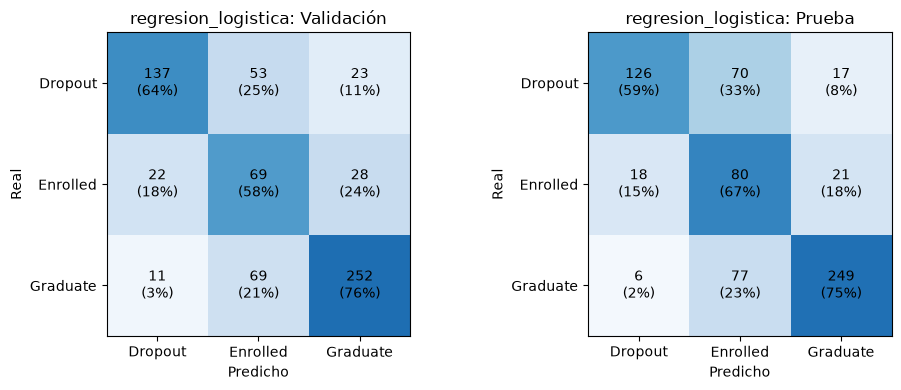

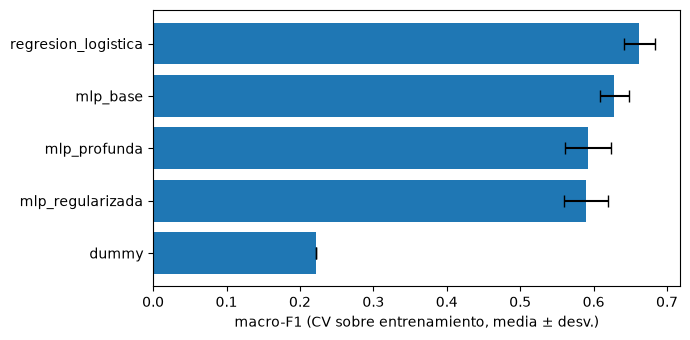

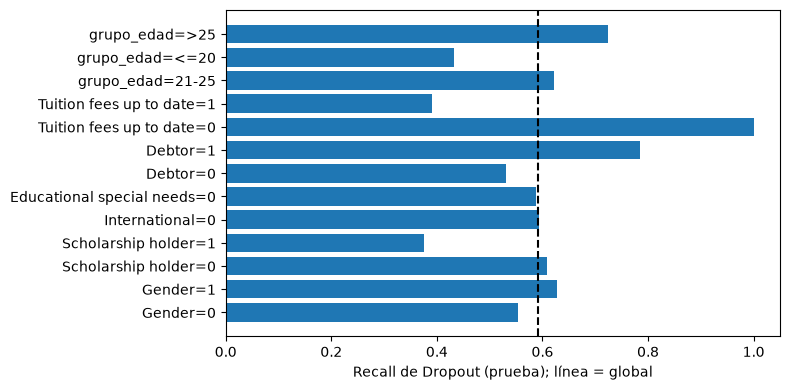

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
FIG = RAIZ / "docs" / "figuras"; FIG.mkdir(parents=True, exist_ok=True)
mejor = json.loads((RAIZ / "modelos" / "mejor_version.json").read_text(encoding="utf-8"))["version"]
ficha = json.loads((RAIZ / "modelos" / "fichas_json" / f"{mejor}.json").read_text(encoding="utf-8"))

# Fig 04: matrices de confusión (validación y prueba, solo lectura de la ficha)
fig, ejes = plt.subplots(1, 2, figsize=(10, 4))
for eje, (titulo, clave) in zip(ejes, [("Validación", "metricas_validacion"), ("Prueba", "metricas_prueba")]):
    m = np.array(ficha[clave]["matriz_confusion"]["valores"]); clases = ficha[clave]["matriz_confusion"]["orden_clases"]
    norm = m / m.sum(axis=1, keepdims=True)
    eje.imshow(norm, vmin=0, vmax=1, cmap="Blues")
    for i in range(3):
        for j in range(3):
            eje.text(j, i, f"{m[i, j]}\n({norm[i, j]:.0%})", ha="center", va="center")
    eje.set_xticks(range(3), clases); eje.set_yticks(range(3), clases)
    eje.set_xlabel("Predicho"); eje.set_ylabel("Real"); eje.set_title(f"{mejor}: {titulo}")
plt.tight_layout(); plt.savefig(FIG / "04_matriz_confusion.png", dpi=150); plt.show()

# Fig 05: variabilidad (CV sobre train)
cv = pd.read_csv(RAIZ / "modelos" / "variabilidad_cv_train.csv").sort_values("macro_f1_cv_media")
plt.figure(figsize=(7, 3.5))
plt.barh(cv["version"], cv["macro_f1_cv_media"], xerr=cv["macro_f1_cv_std"], capsize=4)
plt.xlabel("macro-F1 (CV sobre entrenamiento, media ± desv.)")
plt.tight_layout(); plt.savefig(FIG / "05_variabilidad_cv.png", dpi=150); plt.show()

# Fig 06: recall de Dropout por grupo en prueba (solo grupos con n>=30)
filas = [(f"{c}={v}", d["recall_dropout"]) for c, g in ficha["auditoria_prueba"].items()
         for v, d in g.items() if d["n"] >= 30]
etq, val = zip(*filas)
plt.figure(figsize=(8, 4)); plt.barh(etq, val); plt.axvline(ficha["metricas_prueba"]["recall_por_clase"]["Dropout"], ls="--", c="k")
plt.xlabel("Recall de Dropout (prueba); línea = global"); plt.tight_layout()
plt.savefig(FIG / "06_recall_dropout_por_grupo.png", dpi=150); plt.show()

In [2]:
from src.datos import cargar_y_particionar, separar_xy
from src.evaluacion import comparar_sin_variables, analizar_regla_decision
train, val, _prueba = cargar_y_particionar()           # la prueba no se usa en esta celda
print(comparar_sin_variables(train, {"sin_edad": ["Age at enrollment"],
                                     "sin_pagos": ["Tuition fees up to date", "Debtor"]}).to_string(index=False))
X_val, y_val = separar_xy(val)
print(analizar_regla_decision(joblib.load(RAIZ / "modelos" / f"{mejor}.joblib"), X_val, y_val).to_string(index=False))

escenario  n_variables  macro_f1_cv_media  macro_f1_cv_std
con_todas            8             0.6623           0.0212
 sin_edad            7             0.6552           0.0195
sin_pagos            6             0.6278           0.0212
 peso_dropout  macro_f1_val  recall_Dropout  recall_Enrolled  recall_Graduate
         1.00        0.6514          0.6432           0.5798           0.7590
         1.25        0.6461          0.7136           0.4874           0.7560
         1.50        0.6383          0.7371           0.4454           0.7500
         2.00        0.6094          0.7887           0.3193           0.7410
         2.50        0.5821          0.8545           0.2101           0.7289
         3.00        0.5178          0.8873           0.0672           0.7199
